Exploratory Data Analysis (EDA): Football Matches 2024–2025

## 1. Dataset Profile

In [1]:
import pandas as pd

df = pd.read_csv("data/football_matches_2024_2025.csv")

print(df.shape)
df.info()
print(df.isnull().sum())
display(df.describe(include="all"))

(1941, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   competition_code  1941 non-null   object
 1   competition_name  1941 non-null   object
 2   season            1941 non-null   object
 3   match_id          1941 non-null   int64 
 4   matchday          1941 non-null   int64 
 5   stage             1941 non-null   object
 6   status            1941 non-null   object
 7   date_utc          1941 non-null   object
 8   referee           1941 non-null   object
 9   home_team_id      1941 non-null   int64 
 10  home_team         1941 non-null   object
 11  away_team_id      1941 non-null   int64 
 12  away_team         1941 non-null   object
 13  fulltime_home     1941 non-null   int64 
 14  fulltime_away     1941 non-null   int64 
 15  halftime_home     1941 non-null   int64 
 16  halftime_away     1941 non-null   int64 
 17  goa

,competition_code,competition_name,season,match_id,matchday,stage,status,date_utc,referee,home_team_id,...,fulltime_home,fulltime_away,halftime_home,halftime_away,goal_difference,total_goals,match_outcome,home_points,away_points,referee_id
count,1941,1941,1941,1941.000000,1941.000000,1941,1941,1941,1941,1941.000000,...,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941.000000,1941,1941.000000,1941.000000,1941.000000
unique,6,6,1,NaN,NaN,7,2,1109,158,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,3,NaN,NaN,NaN
top,PL,Premier League,2024/2025,NaN,NaN,REGULAR_SEASON,FINISHED,2025-01-29 20:00:00+00:00,Michael Oliver,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Home Win,NaN,NaN,NaN
freq,380,380,1941,NaN,NaN,1752,1939,18,34,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,832,NaN,NaN,NaN
mean,NaN,NaN,NaN,502366.762494,17.338485,NaN,NaN,NaN,NaN,483.205564,...,1.535806,1.340031,0.699639,0.588357,0.195775,2.875837,NaN,1.524472,1.236991,65.609995
std,NaN,NaN,NaN,7461.271565,11.056850,NaN,NaN,NaN,NaN,1170.086272,...,1.322829,1.205567,0.860319,0.790438,1.880667,1.693997,NaN,1.331631,1.305615,42.866261
min,NaN,NaN,NaN,497410.000000,0.000000,NaN,NaN,NaN,NaN,2.000000,...,0.000000,0.000000,0.000000,0.000000,-6.000000,0.000000,NaN,0.000000,0.000000,-1.000000
25%,NaN,NaN,NaN,498056.000000,7.000000,NaN,NaN,NaN,NaN,67.000000,...,1.000000,0.000000,0.000000,0.000000,-1.000000,2.000000,NaN,0.000000,0.000000,29.000000
50%,NaN,NaN,NaN,498897.000000,17.000000,NaN,NaN,NaN,NaN,109.000000,...,1.000000,1.000000,1.000000,0.000000,0.000000,3.000000,NaN,1.000000,1.000000,61.000000
75%,NaN,NaN,NaN,503126.000000,27.000000,NaN,NaN,NaN,NaN,522.000000,...,2.000000,2.000000,1.000000,1.000000,1.000000,4.000000,NaN,3.000000,3.000000,104.000000


Observations

The dataset contains 1,941 football matches and 23 columns across 6 competitions during the 2024/2025 season. Home teams scored an average of 1.54 goals per match, compared to 1.34 goals for away teams. Home Win was the most frequent match outcome, occurring 832 times. This suggests a possible home advantage, which we will investigate further by comparing home wins, away wins, and draws. Additionally, 1,939 matches have a FINISHED status, while 2 have another status that may need further investigation.

2. Anomaly Detection

In [2]:
print("Missing values:")
print(df.isnull().sum().to_string())

print("Rows with missing values:", df.isnull().any(axis=1).sum())

print("Duplicate rows:", df.duplicated().sum())
print("Duplicate match IDs:", df["match_id"].duplicated().sum())
df["status"].value_counts()

Missing values:
competition_code    0
competition_name    0
season              0
match_id            0
matchday            0
stage               0
status              0
date_utc            0
referee             0
home_team_id        0
home_team           0
away_team_id        0
away_team           0
fulltime_home       0
fulltime_away       0
halftime_home       0
halftime_away       0
goal_difference     0
total_goals         0
match_outcome       0
home_points         0
away_points         0
referee_id          0
Rows with missing values: 0
Duplicate rows: 0
Duplicate match IDs: 0


status
FINISHED    1939
AWARDED        2
Name: count, dtype: int64

The dataset contains no missing values across its 23 columns. There are also no duplicate rows or duplicate match IDs. Therefore, no rows needed to be removed or modified for these issues.

Invalid Values and Match Status

In [3]:
display(df["status"].value_counts())

display(df[df["status"] == "AWARDED"])

status
FINISHED    1939
AWARDED        2
Name: count, dtype: int64

,competition_code,competition_name,season,match_id,matchday,stage,status,date_utc,referee,home_team_id,...,fulltime_home,fulltime_away,halftime_home,halftime_away,goal_difference,total_goals,match_outcome,home_points,away_points,referee_id
1260,BL1,Bundesliga,2024/2025,502494,14,REGULAR_SEASON,AWARDED,2024-12-14 14:30:00+00:00,Martin Petersen,28,...,0,2,0,0,-2,2,Away Win,0,3,102
1676,FL1,Ligue 1,2024/2025,498178,26,REGULAR_SEASON,AWARDED,2025-03-16 16:15:00+00:00,François Letexier,518,...,0,2,0,1,-2,2,Away Win,0,3,128


The dataset contains 1,939 finished matches and 2 awarded matches, both recorded as away wins. Since awarded results may not reflect normal match outcomes, I excluded these 2 matches (2 rows) from the analysis to avoid affecting the comparison between home and away wins. This leaves 1,939 matches for further analysis.

In [4]:
df_clean = df[df["status"] == "FINISHED"].copy()

print(df_clean.shape)

(1939, 23)


## Incorrect Data Types

In [5]:
print("Before:", df_clean["date_utc"].dtype)

df_clean["date_utc"] = pd.to_datetime(df_clean["date_utc"], utc=True, errors="coerce")

print("After:", df_clean["date_utc"].dtype)
print("Invalid dates:", df_clean["date_utc"].isnull().sum())

Before: object
After: datetime64[ns, UTC]
Invalid dates: 0


## Incorrect Data Types Observations

The date_utc column was originally stored as an object instead of a datetime type, affecting all 1,939 remaining rows. I converted it to datetime format to make it easier to analyze match results over time. All dates were converted successfully, with 0 invalid dates.

## Invalid Values

In [6]:
print("Negative goals:", ((df_clean["fulltime_home"] < 0) | (df_clean["fulltime_away"] < 0)).sum())

print("Incorrect total goals:", (df_clean["total_goals"] != df_clean["fulltime_home"] + df_clean["fulltime_away"]).sum())

print("Incorrect goal differences:", (df_clean["goal_difference"] != df_clean["fulltime_home"] - df_clean["fulltime_away"]).sum())

print(df_clean["match_outcome"].value_counts())

expected = df_clean["fulltime_home"].gt(df_clean["fulltime_away"]).map({True: "Home Win", False: "Away Win"})
expected[df_clean["fulltime_home"] == df_clean["fulltime_away"]] = "Draw"

print("Incorrect match outcomes:", (df_clean["match_outcome"] != expected).sum())

Negative goals: 0
Incorrect total goals: 0
Incorrect goal differences: 0
match_outcome
Home Win    832
Away Win    644
Draw        463
Name: count, dtype: int64
Incorrect match outcomes: 0


The dataset contains no negative goal values, incorrect total goals, or incorrect goal differences. There are 832 home wins, 644 away wins, and 463 draws. All match outcomes correctly match their final scores, with 0 inconsistencies found. Therefore, no corrections were needed for these values.

## Inconsistent Formatting

In [7]:
text_cols = ["home_team", "away_team", "competition_name", "match_outcome", "stage", "referee"]

for col in text_cols:
    print(col, "extra spaces:", (df_clean[col] != df_clean[col].str.strip()).sum())
    print(col, "repeated spaces:", df_clean[col].str.contains(r" {2,}").sum())

teams = pd.concat([df_clean["home_team"], df_clean["away_team"]]).drop_duplicates()

variants = teams.groupby(teams.str.lower()).nunique()

print("Team names with capitalization differences:", (variants > 1).sum())

home_team extra spaces: 0
home_team repeated spaces: 0
away_team extra spaces: 0
away_team repeated spaces: 0
competition_name extra spaces: 0
competition_name repeated spaces: 0
match_outcome extra spaces: 0
match_outcome repeated spaces: 0
stage extra spaces: 0
stage repeated spaces: 0
referee extra spaces: 0
referee repeated spaces: 0
Team names with capitalization differences: 0


### Inconsistent Formatting Observations

I checked team names, competition names, match outcomes, stages, and referee names for extra spaces and repeated spaces. I also checked for capitalization differences in team names. No inconsistencies were found in these checks across the 1,939 matches, so no corrections were needed.

## Mixed Units

In [8]:
goal_cols = ["fulltime_home", "fulltime_away", "halftime_home", "halftime_away", "total_goals"]
point_cols = ["home_points", "away_points"]

print("Goal column types:")
print(df_clean[goal_cols].dtypes)

print("Point column types:")
print(df_clean[point_cols].dtypes)

print("Non-integer goals:", ((df_clean[goal_cols] % 1 != 0).any(axis=1)).sum())

print("Unexpected point values:", (~df_clean[point_cols].isin([0, 1, 3])).any(axis=1).sum())

print("Halftime goals exceeding fulltime goals:", (
    (df_clean["halftime_home"] > df_clean["fulltime_home"]) |
    (df_clean["halftime_away"] > df_clean["fulltime_away"])
).sum())

Goal column types:
fulltime_home    int64
fulltime_away    int64
halftime_home    int64
halftime_away    int64
total_goals      int64
dtype: object
Point column types:
home_points    int64
away_points    int64
dtype: object
Non-integer goals: 0
Unexpected point values: 0
Halftime goals exceeding fulltime goals: 0


### Mixed Units Observations

I checked the goal and point columns for inconsistent values. All goal values are stored as integers, and there are no non-integer goals. All points use valid values of 0, 1, or 3. Additionally, no matches have halftime goals exceeding fulltime goals. No suspicious values were found in these checks, so no corrections were needed. The checks did not identify any mixed-unit issues.

Referee ID Anomalies

In [9]:
print("Referee IDs equal to -1:", (df_clean["referee_id"] == -1).sum())
display(df_clean[df_clean["referee_id"] == -1][["match_id", "referee", "referee_id"]])

Referee IDs equal to -1: 3


,match_id,referee,referee_id
409,498634,Unknown,-1
670,498912,Unknown,-1
1060,503346,Unknown,-1


### Referee ID Observations

The dataset contains 3 matches where referee_id is -1 and referee is listed as "Unknown". These values represent missing referee information. Since our research focuses on home advantage and match outcomes rather than referees, I decided to keep these 3 matches and flag the missing referee information instead of removing them.

## 3. Feature Distributions

## Match Outcome Distribution

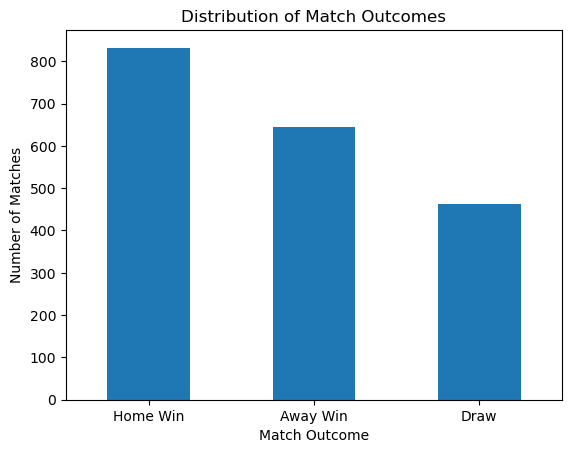

In [10]:
import matplotlib.pyplot as plt
counts = df_clean["match_outcome"].value_counts()

counts.plot(kind="bar")

plt.title("Distribution of Match Outcomes")
plt.xlabel("Match Outcome")
plt.ylabel("Number of Matches")
plt.xticks(rotation=0)
plt.show()

Home wins were the most common match outcome, occurring 832 times, followed by 644 away wins and 463 draws. This suggests that home teams may have an advantage because they won more frequently than away teams. Further analysis is needed to understand whether this pattern is consistent across different leagues.

##Home Goals Distribution

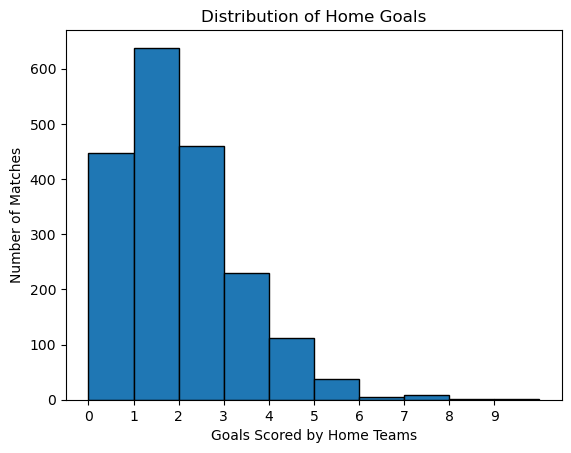

count    1939.000000
mean        1.537390
std         1.322591
min         0.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         9.000000
Name: fulltime_home, dtype: float64
fulltime_home
0    448
1    638
2    460
3    229
4    112
5     37
6      5
7      8
8      1
9      1
Name: count, dtype: int64


In [11]:
goals = df_clean["fulltime_home"]

goals.plot(kind="hist", bins=range(goals.max() + 2), edgecolor="black")

plt.title("Distribution of Home Goals")
plt.xlabel("Goals Scored by Home Teams")
plt.ylabel("Number of Matches")
plt.xticks(range(goals.max() + 1))
plt.show()

print(df_clean["fulltime_home"].describe())
print(df_clean["fulltime_home"].value_counts().sort_index())

Home teams scored an average of 1.54 goals per match, with a median of 1 goal. The distribution is right-skewed, meaning most matches had relatively few home goals, while higher goal counts were less common. Goals ranged from 0 to 9, with only 15 matches having 6 or more home goals. Comparing this distribution with away goals can help us investigate whether playing at home is associated with better scoring performance.

## Away Goals Distribution

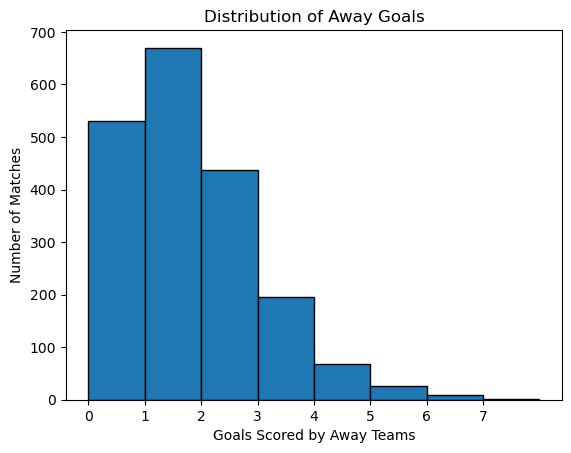

count    1939.000000
mean        1.339350
std         1.206002
min         0.000000
25%         0.000000
50%         1.000000
75%         2.000000
max         7.000000
Name: fulltime_away, dtype: float64
fulltime_away
0    531
1    670
2    438
3    196
4     68
5     26
6      9
7      1
Name: count, dtype: int64


In [12]:
goals = df_clean["fulltime_away"]

goals.plot(kind="hist", bins=range(goals.max() + 2), edgecolor="black")

plt.title("Distribution of Away Goals")
plt.xlabel("Goals Scored by Away Teams")
plt.ylabel("Number of Matches")
plt.xticks(range(goals.max() + 1))
plt.show()

print(goals.describe())
print(goals.value_counts().sort_index())

Away teams scored an average of 1.34 goals per match, with a median of 1 goal. The distribution is right-skewed, meaning most away teams scored relatively few goals, while higher goal counts were less common. Goals ranged from 0 to 7, with only 10 matches having 6 or more away goals. Compared to home teams, which averaged 1.54 goals, away teams scored fewer goals on average.

## Goal Difference Distribution

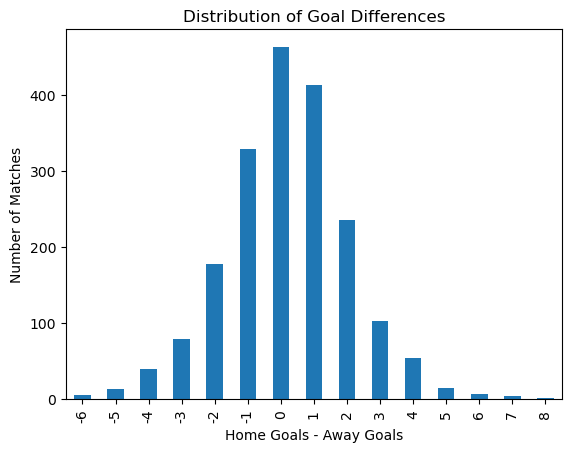

count    1939.000000
mean        0.198040
std         1.880314
min        -6.000000
25%        -1.000000
50%         0.000000
75%         1.000000
max         8.000000
Name: goal_difference, dtype: float64


In [13]:
df_clean["goal_difference"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of Goal Differences")
plt.xlabel("Home Goals - Away Goals")
plt.ylabel("Number of Matches")
plt.show()

print(df_clean["goal_difference"].describe())

The average goal difference was approximately +0.20 goals, while the median was 0. Most matches had goal differences close to zero, indicating that many matches were relatively close. Goal differences ranged from -6 to +8, with large differences being uncommon. The slightly positive average suggests that home teams generally scored more goals than away teams, which may indicate a home-field advantage.

## Competition Distribution

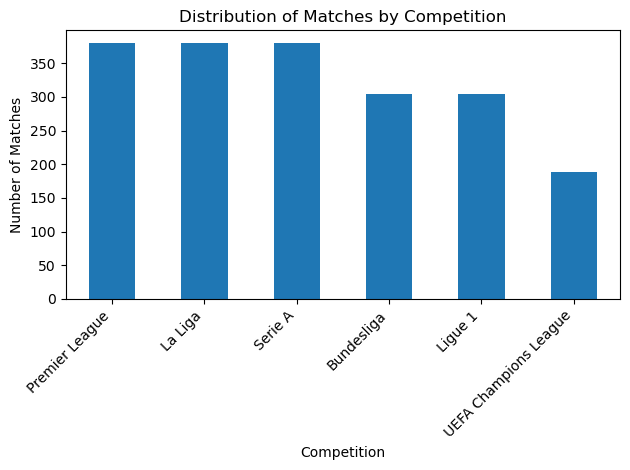

In [14]:
df_clean["competition_name"].value_counts().plot(kind="bar")

plt.title("Distribution of Matches by Competition")
plt.xlabel("Competition")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The Premier League, La Liga, and Serie A each contain 380 matches, while the Bundesliga and Ligue 1 each contain 305 matches. The Champions League has the fewest matches, with 189. Since the competitions have different numbers of matches, comparing raw home-win counts could be misleading. Therefore, comparing home-win percentages across competitions will help us investigate whether home advantage differs between them.

## 4. Relationships Between Home-Win Percentage Across Competitions

competition_name
Bundesliga               38.69
La Liga                  44.47
Ligue 1                  46.89
Premier League           40.79
Serie A                  39.74
UEFA Champions League    50.79
Name: match_outcome, dtype: float64


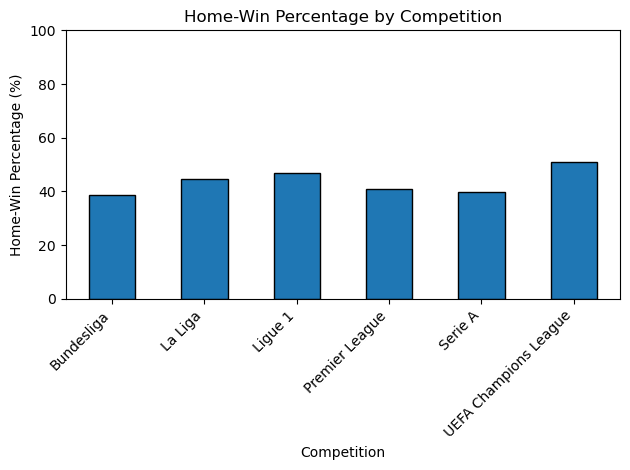

In [15]:
home_win_pct = df_clean.groupby("competition_name")["match_outcome"].apply(
    lambda x: (x == "Home Win").mean() * 100
)

print(home_win_pct.round(2))

home_win_pct.plot(kind="bar", edgecolor="black")

plt.title("Home-Win Percentage by Competition")
plt.xlabel("Competition")
plt.ylabel("Home-Win Percentage (%)")
plt.ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## So what/Expected?
Home-win percentages differed across competitions, with the Champions League highest and Bundesliga lowest. This tells us that home teams don't win at the same frequency in every competition. I expected home-win percentages to vary somewhat across competitions because teams and playing conditions differ. However, I was surprised by the size of the difference, with the Champions League having the highest home-win percentage at 50.79% and the Bundesliga the lowest at 38.69%.

## What Next?
Next, I would compare home-win, away-win, and draw percentages within each competition to see whether home teams actually have a stronger advantage in certain leagues. This would help determine whether the differences in home-win percentages reflect home-field advantage or are partly explained by differences in draw rates.